In [57]:
import torch
import torch_scatter
from torch_geometric.utils import to_networkx
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader

import networkx as nx
import matplotlib.pyplot as plt

torch.manual_seed(666)

## Introduction

For this part of the assignment we will look at how PyTorch Geometric handles batching and how we can use this functionality in our models. We will use the ESOL dataset from MoleculeNet as a test case. The dataset contains molecular graphs, defined through nodes (atoms) and edges (bond connectivity). More information about the data can be found [here](https://pytorch-geometric.readthedocs.io/en/2.5.0/generated/torch_geometric.datasets.MoleculeNet.html). 

Run the cell below to download the dataset and inspect the graphs a little bit!

Dataset name: ESOL(1128)
Number of graphs: 1128
Number of node features: 9
Number of edge features: 3

Graph 0:
---------------------
Number of nodes: 32
Number of edges: 68



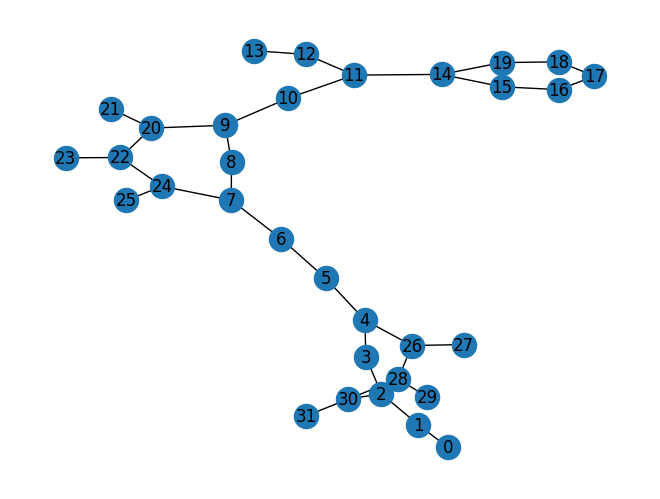


Graph 1:
---------------------
Number of nodes: 15
Number of edges: 32


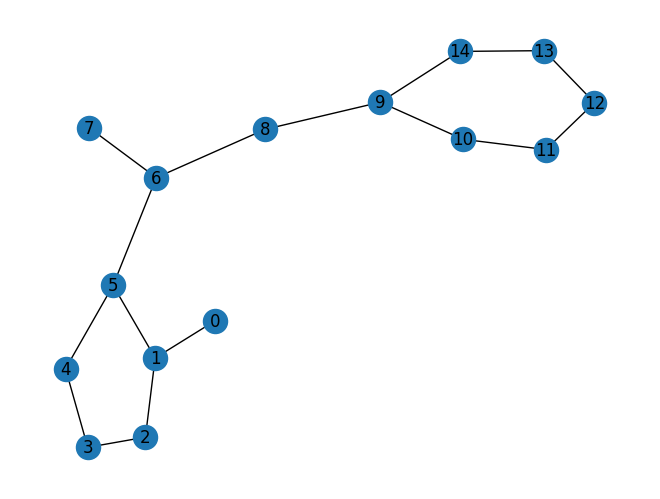

In [58]:
dataset = MoleculeNet(root='data/MoleculeNet', name='ESOL')  # download dataset

# let's look at some dataset statistics
print(f'Dataset name: {dataset}')
print('==============================================')
print(f'Number of graphs: {len(dataset)}')  # nr graphs in dataset
print(f'Number of node features: {dataset.num_node_features}')
print(f'Number of edge features: {dataset.num_edge_features}')
print('==============================================')
print()

# take a look at the first two graphs
graph_index = 0  # first graph
print(f'Graph {graph_index}:')
print('---------------------')
print(f'Number of nodes: {dataset[graph_index].num_nodes}')
print(f'Number of edges: {dataset[graph_index].num_edges}')
print()

# visualize the graph
G = to_networkx(dataset[graph_index], to_undirected=True)
nx.draw(G, with_labels=True)
plt.show()
print()

graph_index = 1  # second graph
print(f'Graph {graph_index}:')
print('---------------------')
print(f'Number of nodes: {dataset[graph_index].num_nodes}')
print(f'Number of edges: {dataset[graph_index].num_edges}')

# visualize the graph
G = to_networkx(dataset[graph_index], to_undirected=True)
nx.draw(G, with_labels=True)
plt.show()

### Question 1

Looking at the graphs and dataset information printed above, please give an interpretation of the following attributes for the ESOL dataset (you can fill in the answers below):

- `num_node_features`
- `num_edge_features`
- `num_nodes`
- `num_edges`

## The PyTorch Geometric Data Format
As we saw, each item in the dataset is a graph. We will now take a closer look at how the data is stored through PyTorch Geometric.

In [59]:
# print a data object
graph_index = 0
print(f"Dataset index: {graph_index}\n")

print(f"Dataset item:\n{dataset[graph_index]}")

Dataset index: 0

Dataset item:
Data(x=[32, 9], edge_index=[2, 68], edge_attr=[68, 3], smiles='OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O ', y=[1, 1])


As we can see, each dataset item contains multiple attributes. In our case we have
- Node feature matrix `x`.
- Graph connectivity matrix `edge_index`. Here, each column represents an edge in the format `(source, target)`
- Edge feature matrix `edge_attr`
- Text representation of the molecule `smiles`
- Target to learn `y` (solubility in this case)

We can access an attribute by calling `dataset[graph_index].<attribute>`, where we replace `<attribute>` with the attribute of interest.


### Question 2

1. Write code to print out the following attributes for the first graph in the dataset.
    - `x`
    - `edge_index`
    - `edge_attr`
    - `y`

2. What are the shapes of the graph attributes? Can you give an interpretation of what the attributes represent in molecular terms?

In [60]:
# Complete the code below for Question 2.1
graph_index = 0  # first graph

x = ...  # TODO: get node features
edge_index = ...    # TODO: get edge indices
edge_features = ...     # TODO: get edge features
target = ...    # TODO: get target property

# print out the attributes of the data object
print(f"Node features: {x}\n")
print(f"Edge indices: {edge_index}\n")
print(f"Edge features: {edge_features}\n")
print(f"Target property: {target}\n")

Node features: Ellipsis

Edge indices: Ellipsis

Edge features: Ellipsis

Target property: Ellipsis



#### *Write your answer for Question 2.2 here!*



## Using the PyTorch Geometric `Dataloader`

Now that we are familiar with the dataset format, we can put our dataset into a dataloader. 

In [61]:
batch_size = 32
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

print(f'Number of batches: {len(loader)}')

first_batch = next(iter(loader))
print(first_batch)  # print the first batch

Number of batches: 36
DataBatch(x=[422, 9], edge_index=[2, 854], edge_attr=[854, 3], smiles=[32], y=[32, 1], batch=[422], ptr=[33])


We see that when we print a batch from the dataloader, we obtain a `DataBatch` object. The `DataBatch` contains the same attributes as our dataset item, however the dimensions have changed! PyTorch Geometric has stacked the graph dimension and the batch dimension on top of each other. For example, the node features `x` now have the shape [num nodes in batch, num_node_features].

To keep track of which features belong to which graph in a batch, the dataloader has an attribute called `batch`. The `batch` attribute has the same shape as the node features, and contains indices of which nodes belong to which graph within the batch.

### Question 3

Answer the following questions (you can add the code in the cell below):

1. Print out the `batch` attribute for the first batch of the dataloader.

2. How many different graphs does the batch contain?

3. How many nodes are there in the first graph?

4. Is the number of nodes in the batch evenly divisible by the number of graphs in the batch? Why/why not?

In [62]:
batch = next(iter(loader))
batch_attr = ...    # TODO: write your code to Question 3.1 here!

print(f'Minibatch .batch attribute:\n {batch_attr}\n')

Minibatch .batch attribute:
 Ellipsis



## Using the `batch` attribute in a model

The `batch` attribute is useful, for example when we would like to predict global properties of the graph by aggregating node features. Say that we have a function $f$ (for example a neural network) that takes in a batch of graphs and outputs updated values for each of the nodes. To aggregate the *local* information of the nodes and make a *global* prediction we need a way to keep track of which nodes belong to which graph in the batch. For this we can use `torch_scatter.scatter` together with the `batch` attribute. Documentation on this function can be found [here](https://pytorch-scatter.readthedocs.io/en/2.0.2/functions/scatter.html).

### Question 4
Below is an implementation of a very simple torch module that passes the node features through a linear layer to project them into a single scalar value for each node. As such, we now have a set of local 1D-features for each node in the batch. We would like our module to output a scalar value for each graph in the batch. 

1. Finalize the implementation in the cell below.
2. Explain in your own words why the tensor shape changes the way it does. 
3. For what purpose could you be interested in aggregating local node information in this way?

In [63]:
class DummyModel(torch.nn.Module):
    ''' 
    A dummy model to illustrate how to use the `batch` attribute.
    '''
    def __init__(self, n_features=9):
        super(DummyModel, self).__init__()

        # here you can add cooler layers, e.g., graph convolutions or similar, but not this is not needed right now,
        # we keep it simple for this example

        self.proj = torch.nn.Linear(n_features, 1)  # project node features to a single value

    def forward(self, batch):
        node_feats = batch.x.float()
        x = ... # TODO: pass node features through the projection layer
        x_shape = ...
        print(f"Shape before aggregation: {x_shape}")

        out = ... # TODO: aggregate through summation
        out_shape = ...
        print(f"Shape after aggregation: {out_shape}")

        # NOTE: here we could add an activation function, but let's keep it simple for now
        return out

f = DummyModel()
batch = next(iter(loader))
out = f(batch)

Shape before aggregation: Ellipsis
Shape after aggregation: Ellipsis
